In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix


In [2]:
df = pd.read_excel("Online Retail.xlsx")

# Display first five rows
print(df.head())

# Dataset information
print(df.info())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----

In [3]:
print("\nDataset Description\n")
print(df.describe())



Dataset Description

            Quantity                 InvoiceDate      UnitPrice     CustomerID
count  541909.000000                      541909  541909.000000  406829.000000
mean        9.552250  2011-07-04 13:34:57.156386       4.611114   15287.690570
min    -80995.000000         2010-12-01 08:26:00  -11062.060000   12346.000000
25%         1.000000         2011-03-28 11:34:00       1.250000   13953.000000
50%         3.000000         2011-07-19 17:17:00       2.080000   15152.000000
75%        10.000000         2011-10-19 11:27:00       4.130000   16791.000000
max     80995.000000         2011-12-09 12:50:00   38970.000000   18287.000000
std       218.081158                         NaN      96.759853    1713.600303


In [4]:
print("\nDataset Shape")
print(df.shape)



Dataset Shape
(541909, 8)


In [5]:
print("\nMissing Values")
print(df.isnull().sum())



Missing Values
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
# Remove missing values
df.dropna(inplace=True)


In [7]:
# Remove duplicate records
df.drop_duplicates(inplace=True)


In [8]:
# Keep only positive Quantity
df = df[df["Quantity"] > 0]


In [9]:
# Keep only positive UnitPrice
df = df[df["UnitPrice"] > 0]


In [10]:
# Remove cancelled invoices
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]


In [11]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

In [12]:
median_value = df["TotalAmount"].median()
df["CustomerSegment"] = np.where(
    df["TotalAmount"] >= median_value,
    "High",
    "Low"
)


In [13]:
encoder = LabelEncoder()

df["Country"] = encoder.fit_transform(df["Country"])

df["StockCode"] = df["StockCode"].astype(str)
df["StockCode"] = encoder.fit_transform(df["StockCode"])
df["CustomerSegment"] = encoder.fit_transform(df["CustomerSegment"])

In [14]:
temp_df = df.copy()

X = temp_df[[
    "Quantity",
    "UnitPrice",
    "Country",
    "StockCode"
]]

# Ensure all columns in X are numeric (float) for the model
X = X.astype(float)

# Align y with the potentially modified X after dropping rows
y = df.loc[temp_df.index, "CustomerSegment"]

In [15]:

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)


In [16]:
model = DecisionTreeClassifier(

    criterion="entropy",

    random_state=42
)

model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

In [17]:
prediction = model.predict(X_test)

In [18]:
print("\nAccuracy")
print(accuracy_score(y_test, prediction))
print("\nClassification Report")
print(classification_report(y_test, prediction))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, prediction))



Accuracy
0.9999745349444226

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     39270
           1       1.00      1.00      1.00     39269

    accuracy                           1.00     78539
   macro avg       1.00      1.00      1.00     78539
weighted avg       1.00      1.00      1.00     78539


Confusion Matrix
[[39270     0]
 [    2 39267]]


In [19]:
importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": model.feature_importances_
})
print("\nFeature Importance")
print(importance)



Feature Importance
     Feature  Importance
0   Quantity    0.485063
1  UnitPrice    0.514920
2    Country    0.000000
3  StockCode    0.000017


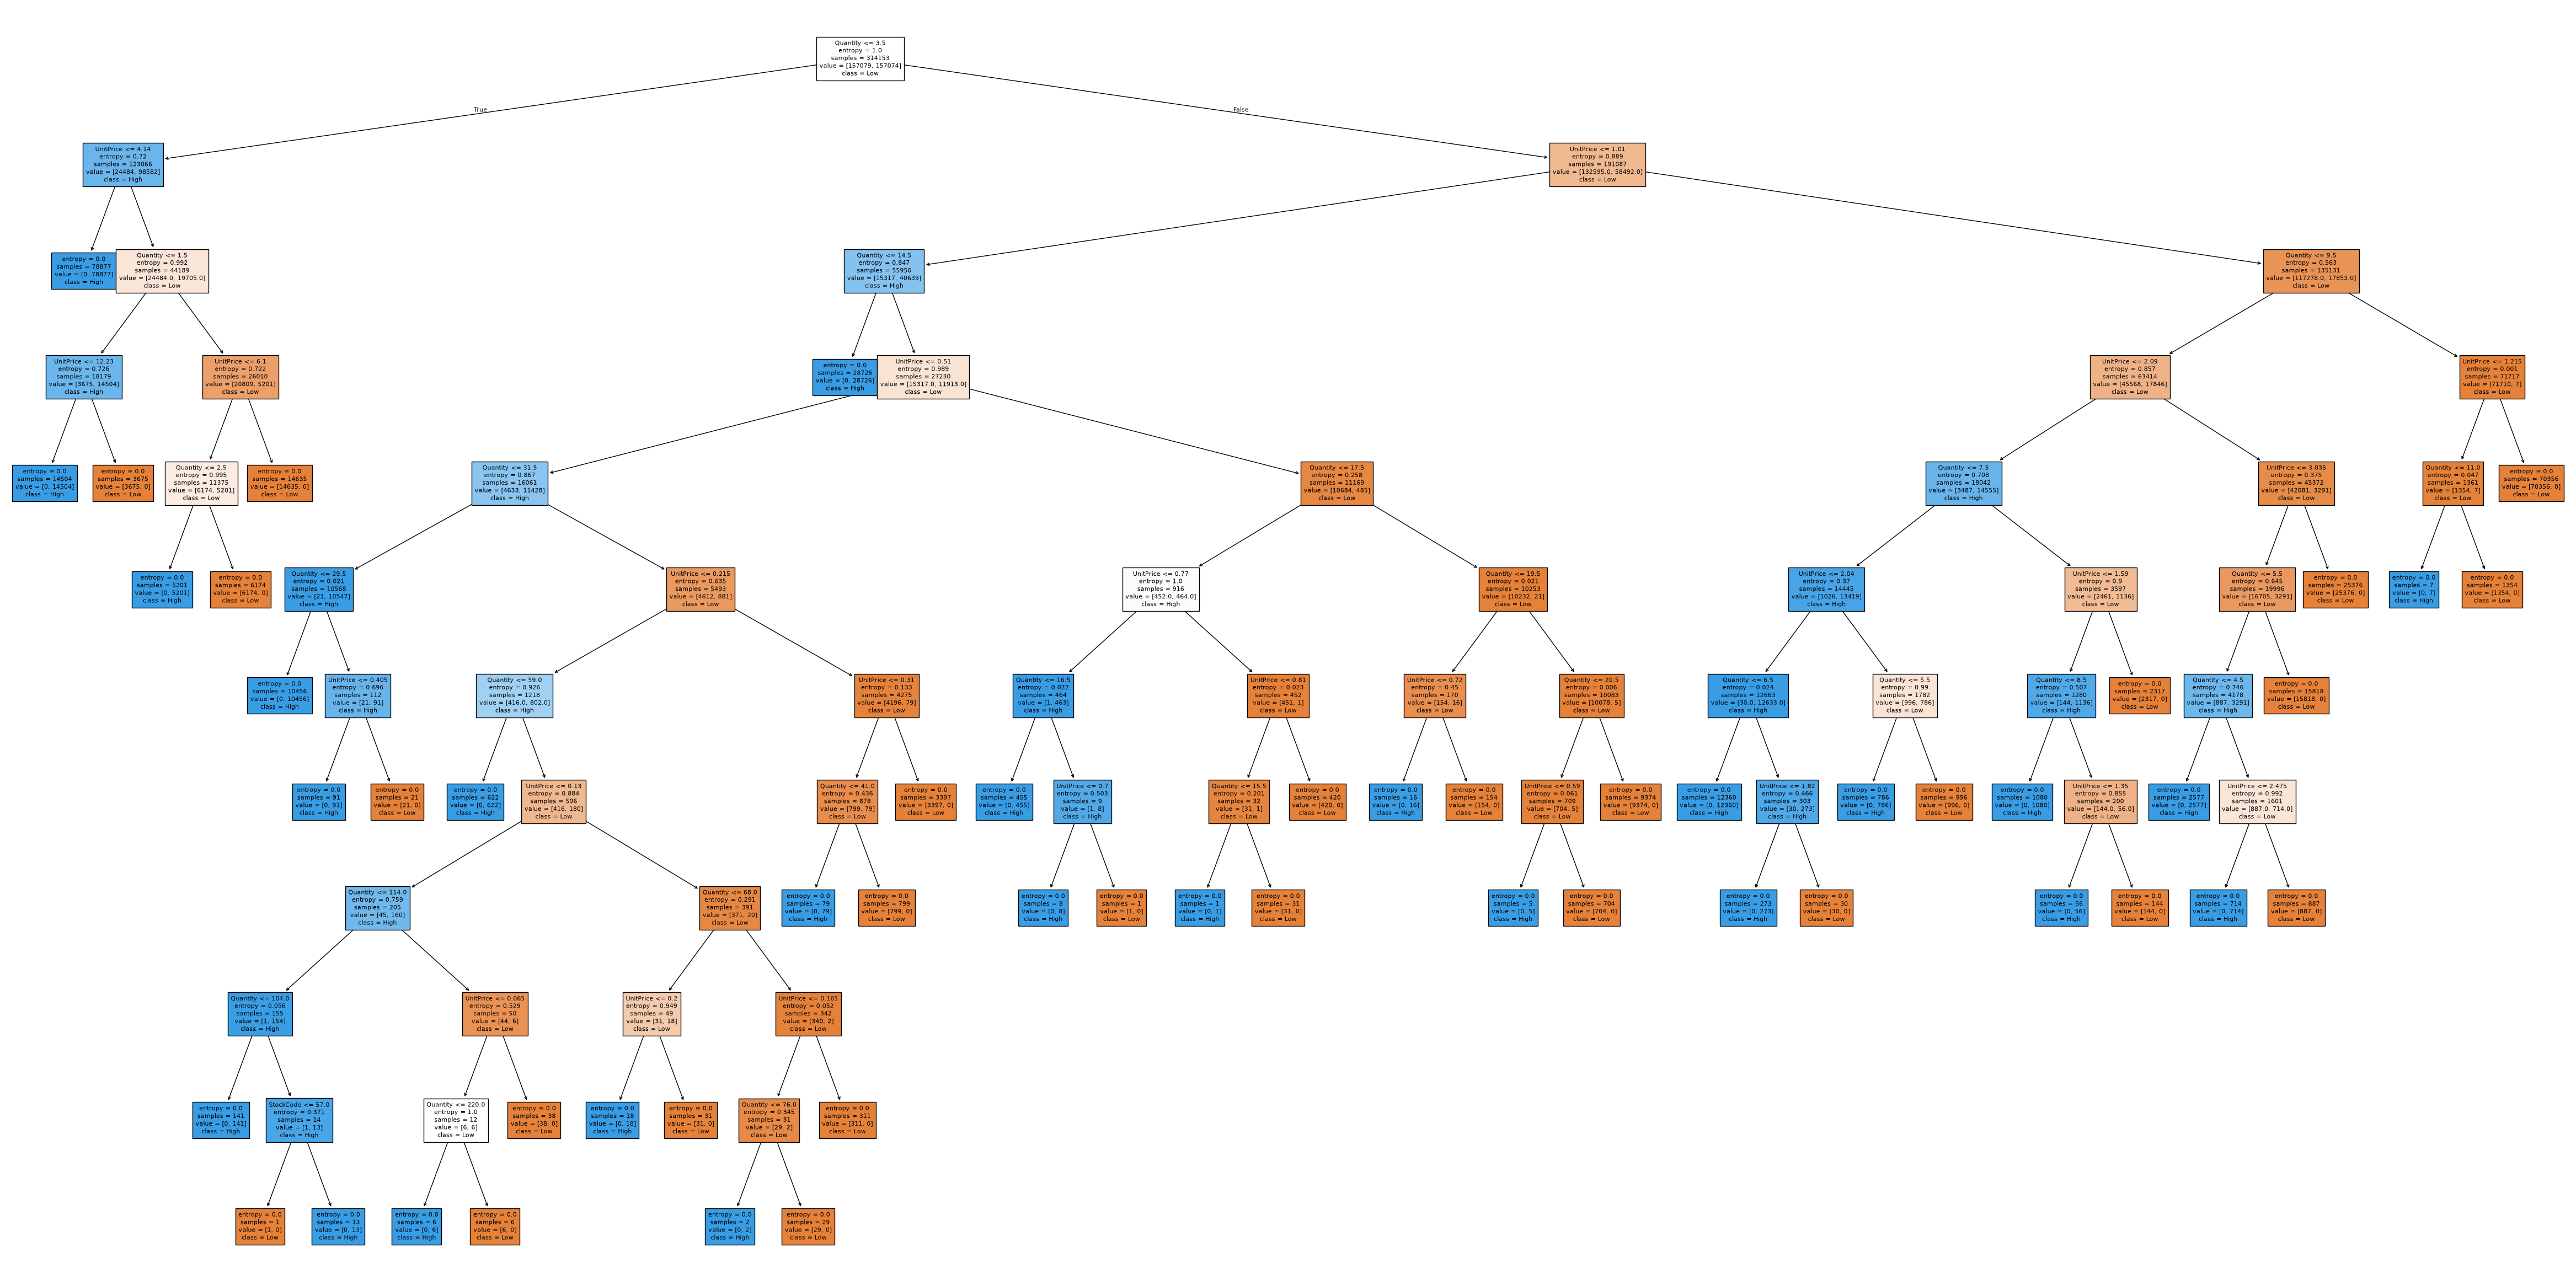

In [20]:
plt.figure(figsize=(60,30))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Low","High"],
    filled=True,
    fontsize=8
)
plt.show()


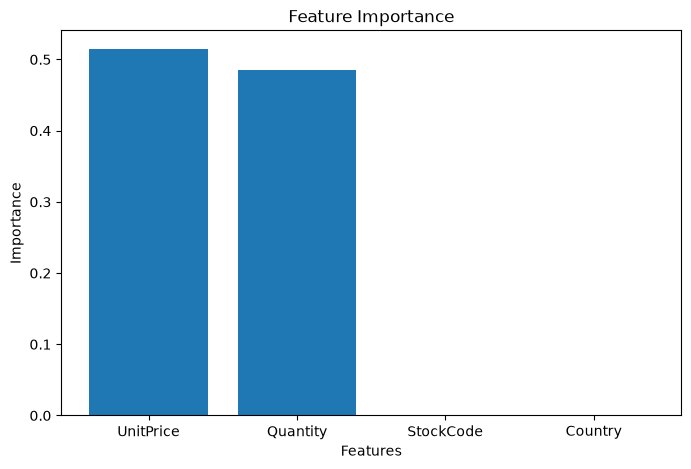

In [21]:
importance = importance.sort_values(
    by="Importance",
    ascending=False
)
plt.figure(figsize=(8,5))
plt.bar(
    importance["Feature"],
    importance["Importance"]
)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance")
plt.show()
